# SPHEREx Blink: Phase 1 Pipeline Validation
**Task:** Block B1 (Find the Data)


This notebook tests IRSA TAP queries, collection auto-discovery, releases datee ranges, and AWS S3 keyparsing cell

## Cell 1: Connect to NASA IRSA & Discover Collections

In [4]:
import json
import pyvo
import pandas as pd

# 1. Connect to NASA IRSA Table Access Protocol (TAP) service
TAP_URL = 'https://irsa.ipac.caltech.edu/TAP'
tap = pyvo.dal.TAPService(TAP_URL)
print('Connected to NASA IRSA TAP Service.\n')

# 2. querying differente collections in spherex.obscore
query = 'SELECT DISTINCT obs_collection FROM spherex.obscore ORDER BY obs_collection'
result = tap.run_sync(query).to_table()

all_collections = [str(row['obs_collection']) for row in result]
print('All collections found in NASA database:')
for col in all_collections:
    print(f'  • {col}')

# 3. Filtering-Keep active science collections starting with spherex_ and exclude _cal
active_collections = [
    col for col in all_collections 
    if col.startswith('spherex_') and not col.endswith('_cal')
]

print('\nActive Science Collections to use in our tool:')
for col in active_collections:
    print(f'  *{col}')

Connected to NASA IRSA TAP Service.

All collections found in NASA database:
  • spherex_dr1
  • spherex_dr1_cal
  • spherex_dr1_deep
  • spherex_qr3
  • spherex_qr3_deep

Active Science Collections to use in our tool:
  *spherex_dr1
  *spherex_dr1_deep
  *spherex_qr3
  *spherex_qr3_deep


## Cell 2: Test releases() Image Counts & MJD-AVG Date Ranges

In [5]:
releases_data = []
for col in active_collections:
    q_rel = f'''
    SELECT COUNT(*) as n_images, MIN(t_min) as min_mjd, MAX(t_max) as max_mjd 
    FROM spherex.obscore 
    WHERE obs_collection = \'{col}\'
    '''
    res_rel = tap.run_sync(q_rel).to_table()
    row = res_rel[0]
    info = {
        'collection': col,
        'n_images': int(row['n_images']),
        'min_mjd': float(row['min_mjd']),
        'max_mjd': float(row['max_mjd'])
    }
    releases_data.append(info)

releases_df = pd.DataFrame(releases_data)
print(releases_df.to_string(index=False))

      collection  n_images      min_mjd      max_mjd
     spherex_dr1    945725 60789.750762 61174.492758
spherex_dr1_deep    233681 60789.771067 61174.504714
     spherex_qr3    362124 61174.506011 61318.002720
spherex_qr3_deep     86700 61174.532694 61317.970958


## Cell 3: Validate Barnard\'s Star (QR2 Deprecated vs QR3/DR1 Active)

In [6]:
ra_barnard = 269.452083
dec_barnard = 4.693389

# 1. Verify QR2 gives 0 rows (confirms it is deprecated)
q_qr2 = f'''
SELECT obs_id, obs_collection, energy_bandpassname 
FROM spherex.obscore 
WHERE obs_collection IN (\'spherex_qr2\', \'spherex_qr2_deep\')
  AND 1 = CONTAINS(POINT(\'ICRS\', {ra_barnard}, {dec_barnard}), s_region)
'''
res_qr2 = tap.run_sync(q_qr2).to_table()
print(f'QR2 search results count: {len(res_qr2)} (Expected: 0)\n')

# 2. Search active collections (QR3, DR1)
cols_str = "\', \'".join(active_collections)
q_active = f'''
SELECT obs_id, obs_collection, energy_bandpassname, t_min, t_max 
FROM spherex.obscore 
WHERE obs_collection IN (\'{cols_str}\')
  AND 1 = CONTAINS(POINT(\'ICRS\', {ra_barnard}, {dec_barnard}), s_region)
'''
res_active = tap.run_sync(q_active).to_table()
print(f'Active collections search count: {len(res_active)}')
df_active = res_active.to_pandas()
print('\nExposures per detector:')
print(df_active['energy_bandpassname'].value_counts())

QR2 search results count: 0 (Expected: 0)

Active collections search count: 363

Exposures per detector:
energy_bandpassname
SPHEREx-D2    62
SPHEREx-D5    62
SPHEREx-D3    60
SPHEREx-D1    60
SPHEREx-D4    60
SPHEREx-D6    59
Name: count, dtype: int64


## Cell 4: Test AWS S3 Key Extraction

In [7]:
q_cloud = f"""
SELECT TOP 5 obs_id, obs_collection, energy_bandpassname, cloud_access 
FROM spherex.obscore 
WHERE obs_collection IN ('{cols_str}')
  AND 1 = CONTAINS(POINT('ICRS', {ra_barnard}, {dec_barnard}), s_region)
"""
res_cloud = tap.run_sync(q_cloud).to_table()
for r in res_cloud:
    print("obs_id:", r['obs_id'], "-> raw value:", repr(r['cloud_access']))

obs_id: 2025W33_2C_0321_1 -> raw value: ''
obs_id: 2025W33_2C_0321_1 -> raw value: ''
obs_id: 2025W33_2C_0321_2 -> raw value: ''
obs_id: 2025W33_2C_0321_2 -> raw value: ''
obs_id: 2025W33_2C_0321_3 -> raw value: ''


In [8]:
import io
import json
import requests
from astropy.io import votable

SIA_URL = "https://irsa.ipac.caltech.edu/SIA"

print("Querying IRSA SIA2 for Barnard's Star in spherex_dr1...")
params = {
    "COLLECTION": "spherex_dr1",
    "POS": f"CIRCLE {ra_barnard} {dec_barnard} 0.0005",
    "RESPONSEFORMAT": "VOTABLE"
}

response = requests.get(SIA_URL, params=params, timeout=60)
table = votable.parse_single_table(io.BytesIO(response.content)).to_table(use_names_over_ids=True)

print(f"SIA2 returned {len(table)} exposures. Inspecting first 3:")
for row in table[:3]:
    obs_id = row['obs_id']
    raw_ca = str(row['cloud_access'])
    print(f"\nobs_id: {obs_id}")
    print(f"raw cloud_access: {raw_ca[:80]}...")
    
    ca = json.loads(raw_ca)
    s3_key = ca['aws']['key']
    print(f" -> S3 Key: {s3_key}")
    print(f" -> Full AWS URL: https://nasa-irsa-spherex.s3.us-east-1.amazonaws.com/{s3_key}")

Querying IRSA SIA2 for Barnard's Star in spherex_dr1...
SIA2 returned 240 exposures. Inspecting first 3:

obs_id: 2025W33_2C_0321_1
raw cloud_access: {"aws": {"bucket_name": "nasa-irsa-spherex", "key":"dr1/level2/2025W33_2C/l2b-v2...
 -> S3 Key: dr1/level2/2025W33_2C/l2b-v27-2026-228/6/level2_2025W33_2C_0321_1D6_spx_l2b-v27-2026-228.fits
 -> Full AWS URL: https://nasa-irsa-spherex.s3.us-east-1.amazonaws.com/dr1/level2/2025W33_2C/l2b-v27-2026-228/6/level2_2025W33_2C_0321_1D6_spx_l2b-v27-2026-228.fits

obs_id: 2025W33_2C_0321_1
raw cloud_access: {"aws": {"bucket_name": "nasa-irsa-spherex", "key":"dr1/level2/2025W33_2C/l2b-v2...
 -> S3 Key: dr1/level2/2025W33_2C/l2b-v27-2026-228/3/level2_2025W33_2C_0321_1D3_spx_l2b-v27-2026-228.fits
 -> Full AWS URL: https://nasa-irsa-spherex.s3.us-east-1.amazonaws.com/dr1/level2/2025W33_2C/l2b-v27-2026-228/3/level2_2025W33_2C_0321_1D3_spx_l2b-v27-2026-228.fits

obs_id: 2025W33_2C_0321_2
raw cloud_access: {"aws": {"bucket_name": "nasa-irsa-spherex", "key"

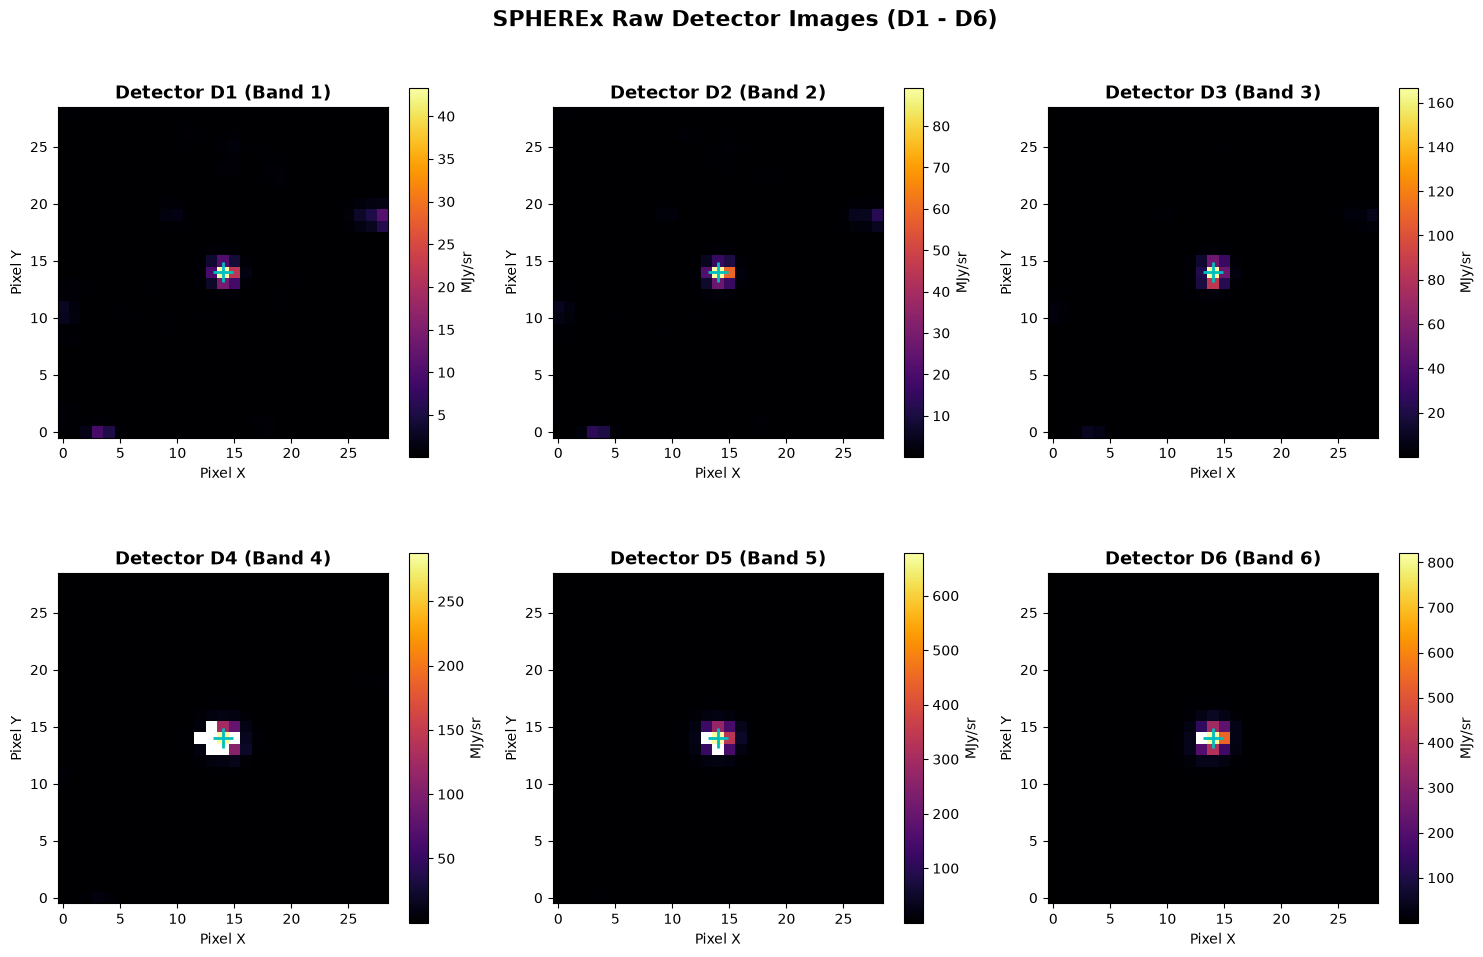


--- Raw Pixel Surface Brightness Table (MJy/sr) ---


,Detector,"Center Pixel (14,14)",Min Pixel,Max Pixel,Std Dev (Noise)
0,D1,43.345 MJy/sr,0.096 MJy/sr,43.345 MJy/sr,1.933
1,D2,89.284 MJy/sr,0.081 MJy/sr,89.284 MJy/sr,4.036
2,D3,166.757 MJy/sr,0.044 MJy/sr,166.757 MJy/sr,7.104
3,D4,287.110 MJy/sr,0.045 MJy/sr,287.110 MJy/sr,11.829
4,D5,677.375 MJy/sr,0.070 MJy/sr,677.375 MJy/sr,29.318
5,D6,819.861 MJy/sr,0.100 MJy/sr,819.861 MJy/sr,40.347


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from pathlib import Path

# Load raw 29x29 pixel arrays across all 6 detectors (D1 to D6)
# Target: RW Aurigae / WISE 0855 (which have all 6 cameras observed)
target_path = Path("/Users/govindapandey/Desktop/Desktop/SphereX_PlanetX/frontend/frames/rw_aur")
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

pixel_summary = []

for d in range(1, 7):
    fits_file = target_path / f"d{d}" / "epoch0.fits"
    with fits.open(fits_file) as hdul:
        raw_data = hdul['IMAGE'].data
        
        # Display the 29x29 raw pixel image
        ax = axes[d - 1]
        im = ax.imshow(raw_data, cmap='inferno', origin='lower')
        fig.colorbar(im, ax=ax, label='MJy/sr', shrink=0.8)
        
        ax.set_title(f"Detector D{d} (Band {d})", fontsize=13, fontweight='bold')
        ax.set_xlabel("Pixel X")
        ax.set_ylabel("Pixel Y")
        
        # Mark center pixel (14, 14)
        ax.plot(14, 14, 'c+', markersize=14, markeredgewidth=2)
        
        # Record center pixel values for DataFrame
        pixel_summary.append({
            "Detector": f"D{d}",
            "Center Pixel (14,14)": f"{raw_data[14, 14]:.3f} MJy/sr",
            "Min Pixel": f"{np.nanmin(raw_data):.3f} MJy/sr",
            "Max Pixel": f"{np.nanmax(raw_data):.3f} MJy/sr",
            "Std Dev (Noise)": f"{np.nanstd(raw_data):.3f}"
        })

plt.suptitle("SPHEREx Raw Detector Images (D1 - D6)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Display the pixel values table as a DataFrame
df_pixels = pd.DataFrame(pixel_summary)
print("\n--- Raw Pixel Surface Brightness Table (MJy/sr) ---")
display(df_pixels)